# StyleBot 06: sistema de recomendación

**Responsable:** Luis Angel Mendosa Gaytán.

Corresponde a la **sección 6** de `E1_StyleBot.ipynb`: recomendador de cinco prendas similares, Precision@5 en validación y prueba, comparación contra recomendaciones aleatorias y ejemplos de aciertos y fallos. El notebook completo con explicación es `04_no_supervisado.ipynb`.

**Uso de las categorías reales:** solo sirven para analizar y evaluar (nombrar grupos por su categoría mayoritaria, pureza, ARI, NMI, Precision@5 y ejemplos). No intervienen en K-Means ni en la búsqueda de recomendaciones.

**Cómo usarlo:** abrir en Google Colab y ejecutar todas las celdas de arriba hacia abajo.

## 1 Carga común de datos

Celdas comunes del equipo (iguales a `01_datos.ipynb` y a la sección 1 de `E1_StyleBot.ipynb`). La última confirma que la división coincide con la del líder.

In [1]:
import numpy as np
from sklearn.model_selection import train_test_split

SEMILLA = 42
CATEGORIAS = [
    "Camiseta", "Pantalón", "Suéter", "Vestido", "Abrigo",
    "Sandalia", "Camisa", "Tenis", "Bolso", "Botín"
]

def preparar_datos_stylebot(X_base, y_base, X_prueba, y_prueba):
    """Divide los 60,000 ejemplos originales y conserva la prueba oficial."""
    assert X_base.shape == (60000, 28, 28)
    assert y_base.shape == (60000,)
    assert X_prueba.shape == (10000, 28, 28)
    assert y_prueba.shape == (10000,)
    assert X_base.dtype == np.uint8 and X_prueba.dtype == np.uint8

    # Los índices permiten identificar exactamente las imágenes de cada parte.
    indices = np.arange(len(y_base), dtype=np.int64)
    idx_train, idx_val = train_test_split(
        indices, test_size=0.20, random_state=SEMILLA, stratify=y_base
    )

    # Normalizar una sola vez: uint8 de 0 a 255 -> float32 de 0 a 1.
    datos = {
        "X_train": X_base[idx_train].astype(np.float32) / np.float32(255.0),
        "y_train": y_base[idx_train].copy(),
        "X_val": X_base[idx_val].astype(np.float32) / np.float32(255.0),
        "y_val": y_base[idx_val].copy(),
        "X_test": X_prueba.astype(np.float32) / np.float32(255.0),
        "y_test": y_prueba.copy(),
        "idx_train": idx_train,
        "idx_val": idx_val,
        # Estos índices pertenecen al archivo de prueba, no al de entrenamiento.
        "idx_test": np.arange(len(y_prueba), dtype=np.int64),
    }
    return datos

def cargar_datos_stylebot():
    """Descarga Fashion-MNIST automáticamente mediante TensorFlow/Keras."""
    from tensorflow.keras.datasets import fashion_mnist
    (X_base, y_base), (X_prueba, y_prueba) = fashion_mnist.load_data()
    return preparar_datos_stylebot(X_base, y_base, X_prueba, y_prueba)


In [2]:
datos = cargar_datos_stylebot()
X_train, y_train = datos["X_train"], datos["y_train"]
X_val, y_val = datos["X_val"], datos["y_val"]
X_test, y_test = datos["X_test"], datos["y_test"]

print("Entrenamiento:", X_train.shape, y_train.shape)
print("Validación:   ", X_val.shape, y_val.shape)
print("Prueba:       ", X_test.shape, y_test.shape)
print("Píxeles:", X_train.dtype, "de", X_train.min(), "a", X_train.max())

Entrenamiento: (48000, 28, 28) (48000,)
Validación:    (12000, 28, 28) (12000,)
Prueba:        (10000, 28, 28) (10000,)
Píxeles: float32 de 0.0 a 1.0


In [3]:
# Esta comprobación NO evalúa modelos: verifica la preparación de datos.
assert len(np.intersect1d(datos["idx_train"], datos["idx_val"])) == 0
assert len(np.union1d(datos["idx_train"], datos["idx_val"])) == 60000

comprobaciones = []
for nombre, X, y, cantidad in [
    ("entrenamiento", X_train, y_train, 48000),
    ("validacion", X_val, y_val, 12000),
    ("prueba", X_test, y_test, 10000),
]:
    assert X.shape == (cantidad, 28, 28)
    assert y.shape == (cantidad,)
    assert X.dtype == np.float32
    assert np.isfinite(X).all()
    assert X.min() >= 0.0 and X.max() <= 1.0
    assert np.isin(y, np.arange(10)).all()
    conteos = np.bincount(y, minlength=10)
    assert np.all(conteos == cantidad // 10)
    comprobaciones.append({
        "conjunto": nombre, "imagenes": cantidad,
        "forma_imagen": "28x28", "tipo_pixeles": str(X.dtype),
        "minimo": float(X.min()), "maximo": float(X.max()),
        "valores_no_finitos": int((~np.isfinite(X)).sum()),
        "etiquetas_invalidas": int((~np.isin(y, np.arange(10))).sum()),
    })
    print(nombre, "OK:", cantidad, "imágenes;", conteos.tolist(), "por categoría")

print("OK: entrenamiento y validación no comparten índices.")
print("La prueba conserva las 10,000 imágenes del archivo oficial de prueba.")
print("Estas revisiones no demuestran ausencia de imágenes duplicadas o problemas visuales.")


entrenamiento OK: 48000 imágenes; [4800, 4800, 4800, 4800, 4800, 4800, 4800, 4800, 4800, 4800] por categoría
validacion OK: 12000 imágenes; [1200, 1200, 1200, 1200, 1200, 1200, 1200, 1200, 1200, 1200] por categoría
prueba OK: 10000 imágenes; [1000, 1000, 1000, 1000, 1000, 1000, 1000, 1000, 1000, 1000] por categoría
OK: entrenamiento y validación no comparten índices.
La prueba conserva las 10,000 imágenes del archivo oficial de prueba.
Estas revisiones no demuestran ausencia de imágenes duplicadas o problemas visuales.


In [4]:
print("ID | Categoría | Entrenamiento | Validación | Prueba")
conteo_clases = []
for identificador, categoria in enumerate(CATEGORIAS):
    fila = {
        "id": identificador, "categoria": categoria,
        "entrenamiento": int(np.sum(y_train == identificador)),
        "validacion": int(np.sum(y_val == identificador)),
        "prueba": int(np.sum(y_test == identificador)),
    }
    conteo_clases.append(fila)
    print(f"{identificador:2} | {categoria:9} | {fila['entrenamiento']:5} | {fila['validacion']:5} | {fila['prueba']:5}")

ID | Categoría | Entrenamiento | Validación | Prueba
 0 | Camiseta  |  4800 |  1200 |  1000
 1 | Pantalón  |  4800 |  1200 |  1000
 2 | Suéter    |  4800 |  1200 |  1000
 3 | Vestido   |  4800 |  1200 |  1000
 4 | Abrigo    |  4800 |  1200 |  1000
 5 | Sandalia  |  4800 |  1200 |  1000
 6 | Camisa    |  4800 |  1200 |  1000
 7 | Tenis     |  4800 |  1200 |  1000
 8 | Bolso     |  4800 |  1200 |  1000
 9 | Botín     |  4800 |  1200 |  1000


In [5]:
import hashlib

# Huellas publicadas por el líder en datos/protocolo_datos.json
HUELLAS_EQUIPO = {
    "idx_train": "1c0cffec1476c830767b282ef3e3354d14cb1e3e2ecb436f13ee8537f0de19c9",
    "idx_val": "e0f8e8bab9913b94050db422b1a42d5223f440f15b110f7ae060debf1332089f",
    "idx_test": "9e1c19b3fdc185411bd1a987deb6a9fda2531116aac060a84c4d878854d1c099",
}
for nombre, esperada in HUELLAS_EQUIPO.items():
    obtenida = hashlib.sha256(datos[nombre].astype("<i8").tobytes()).hexdigest()
    print(f"{nombre}: {'coincide' if obtenida == esperada else 'NO coincide'}")
    assert obtenida == esperada, (
        "La división no coincide con la del equipo. Revisar versiones con el líder antes de seguir."
    )
print("OK: misma división que el resto del equipo.")

idx_train: coincide
idx_val: coincide
idx_test: coincide
OK: misma división que el resto del equipo.


## Requisitos de la sección 5

Para que este notebook funcione solo, se repiten las funciones, el PCA de 50 componentes y el ajuste de K-Means de la sección 5, con la misma semilla. Dan exactamente los mismos grupos.

### 5.1 Funciones de agrupamiento y recomendación

Las mismas funciones están en `src/recomendador_stylebot.py` para la integración.

- `ajustar_pca`: PCA ajustado solo con entrenamiento.
- `ajustar_kmeans` y `metricas_agrupamiento`: K-Means y su comparación contra las categorías reales (pureza, ARI y NMI).
- `construir_recomendador` y `recomendar`: búsqueda de las prendas más cercanas en el catálogo.
- `recomendar_mismo_grupo`: variante que busca solo dentro del mismo grupo de K-Means.
- `recomendaciones_aleatorias` y `precision_en_k`: línea base y métrica.

In [6]:
import numpy as np
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import adjusted_rand_score, normalized_mutual_info_score
from sklearn.neighbors import NearestNeighbors

SEMILLA = 42


def a_vectores(X):
    """(n, 28, 28) -> (n, 784). No vuelve a normalizar: los píxeles ya están entre 0 y 1."""
    return X.reshape(len(X), -1)


def ajustar_pca(X_train, n_componentes=50, semilla=SEMILLA):
    """Ajusta PCA solo con entrenamiento. Validación y prueba únicamente se transforman."""
    pca = PCA(n_components=n_componentes, random_state=semilla)
    pca.fit(a_vectores(X_train))
    return pca


def ajustar_kmeans(Z_train, k=10, semilla=SEMILLA, n_init=10):
    """K-Means sobre las características de entrenamiento."""
    modelo = KMeans(n_clusters=k, n_init=n_init, random_state=semilla)
    modelo.fit(Z_train)
    return modelo


def tabla_contingencia(grupos, y, k=10, n_categorias=10):
    """Filas = grupos de K-Means, columnas = categorías reales."""
    tabla = np.zeros((k, n_categorias), dtype=np.int64)
    np.add.at(tabla, (grupos, y), 1)
    return tabla


def metricas_agrupamiento(grupos, y, k=10):
    """Pureza, ARI y NMI. Las etiquetas solo se usan para evaluar, no para agrupar."""
    tabla = tabla_contingencia(grupos, y, k)
    return {
        "pureza": float(tabla.max(axis=1).sum() / tabla.sum()),
        "ari": float(adjusted_rand_score(y, grupos)),
        "nmi": float(normalized_mutual_info_score(y, grupos)),
    }


def construir_recomendador(Z_catalogo, metrica="cosine"):
    """Índice de vecinos más cercanos sobre el catálogo (entrenamiento)."""
    return NearestNeighbors(metric=metrica, algorithm="brute").fit(Z_catalogo)


def recomendar(indice, Z_consultas, k=5):
    """Devuelve, para cada consulta, las posiciones de las k prendas más parecidas del catálogo."""
    _, posiciones = indice.kneighbors(Z_consultas, n_neighbors=k)
    return posiciones


def recomendar_mismo_grupo(Z_catalogo, grupos_catalogo, Z_consultas, grupos_consultas,
                           k=5, metrica="cosine"):
    """Variante: busca vecinos solo entre las prendas del mismo grupo de K-Means."""
    posiciones = np.empty((len(Z_consultas), k), dtype=np.int64)
    for g in np.unique(grupos_consultas):
        en_grupo = np.flatnonzero(grupos_catalogo == g)
        consultas = np.flatnonzero(grupos_consultas == g)
        indice = construir_recomendador(Z_catalogo[en_grupo], metrica)
        _, locales = indice.kneighbors(Z_consultas[consultas], n_neighbors=k)
        posiciones[consultas] = en_grupo[locales]
    return posiciones


def recomendaciones_aleatorias(n_consultas, n_catalogo, k=5, semilla=SEMILLA):
    """Línea base: k prendas del catálogo elegidas al azar, sin repetir dentro de cada consulta."""
    rng = np.random.default_rng(semilla)
    return np.stack([rng.choice(n_catalogo, size=k, replace=False) for _ in range(n_consultas)])


def aciertos(y_consultas, y_catalogo, posiciones):
    """Matriz booleana: True si la recomendación es de la misma categoría que la consulta."""
    return y_catalogo[posiciones] == y_consultas[:, None]


def precision_en_k(y_consultas, y_catalogo, posiciones):
    """Precision@k promedio: fracción de recomendaciones de la misma categoría."""
    return float(aciertos(y_consultas, y_catalogo, posiciones).mean())

# Carpeta de resultados de esta parte
from pathlib import Path
import csv

CARPETA_NO_SUPERVISADO = Path("StyleBot_agrupamiento_generado")
for subcarpeta in ["resultados/tablas", "resultados/graficas"]:
    (CARPETA_NO_SUPERVISADO / subcarpeta).mkdir(parents=True, exist_ok=True)

def guardar_tabla_ns(nombre, filas):
    ruta = CARPETA_NO_SUPERVISADO / "resultados/tablas" / nombre
    with ruta.open("w", newline="", encoding="utf-8-sig") as archivo:
        escritor = csv.DictWriter(archivo, fieldnames=list(filas[0].keys()))
        escritor.writeheader()
        escritor.writerows(filas)

def guardar_figura_ns(fig, nombre):
    fig.savefig(CARPETA_NO_SUPERVISADO / "resultados/graficas" / nombre, dpi=150, bbox_inches="tight")

### 5.2 Características: PCA de 50 componentes

Misma configuración que `02_caracteristicas.ipynb`: 784 píxeles reducidos a 50 componentes, ajustando solo con entrenamiento.

In [7]:
# PCA propio de esta sección. No se reutiliza X_train_pca porque en la sección 4
# (aprendizaje clásico) ese nombre se reescribe con 100 componentes.
import time
from sklearn.decomposition import PCA

X_train_flat_ns = X_train.reshape(len(X_train), -1)
pca = PCA(n_components=50, random_state=SEMILLA).fit(X_train_flat_ns)
Z_train = pca.transform(X_train_flat_ns)
Z_val = pca.transform(X_val.reshape(len(X_val), -1))
Z_test = pca.transform(X_test.reshape(len(X_test), -1))
print("PCA 50 componentes, varianza conservada:", f"{pca.explained_variance_ratio_.sum():.2%}")
print("Características:", Z_train.shape, Z_val.shape, Z_test.shape)

PCA 50 componentes, varianza conservada: 86.27%
Características: (48000, 50) (12000, 50) (10000, 50)


### K-Means con 10 grupos

In [8]:
# K-Means con 10 grupos, igual que en la sección 5.3.3 (05_aprendizaje_no_supervisado.ipynb).
# Se necesita para la variante del recomendador que busca dentro del mismo grupo.
import numpy as np
import matplotlib.pyplot as plt

kmeans = ajustar_kmeans(Z_train, k=10, n_init=10)
grupos_train = kmeans.labels_
grupos_val = kmeans.predict(Z_val)
print("Imágenes por grupo en entrenamiento:", np.bincount(grupos_train, minlength=10).tolist())

Imágenes por grupo en entrenamiento: [7265, 5236, 2075, 6226, 7708, 5933, 2339, 5881, 3447, 1890]


## 6 Sistema de recomendación

### 6.1 Recomendador de prendas similares

El **catálogo** son las 48,000 imágenes de entrenamiento. Para una imagen de consulta:

1. Se aplana a 784 píxeles y se transforma con el mismo PCA.
2. Se calculan las distancias a todas las prendas del catálogo.
3. Se devuelven las cinco más cercanas.

Las consultas vienen de validación o prueba, así que nunca son parte del catálogo. El recomendador no usa etiquetas; la categoría solo aparece en los títulos para revisar el resultado.

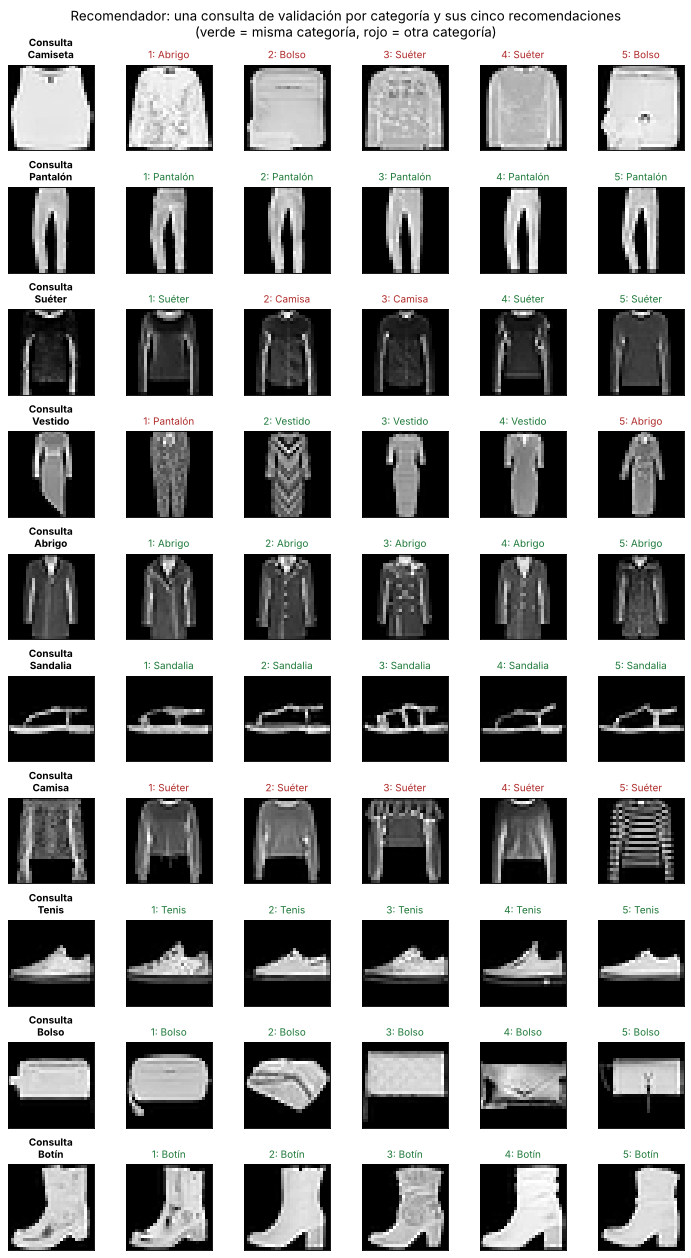

In [9]:
indice_pca_coseno = construir_recomendador(Z_train, metrica="cosine")

def recomendar_prendas(imagen, k=5):
    """Recibe una imagen 28 x 28 con píxeles entre 0 y 1 y devuelve posiciones del catálogo."""
    z = pca.transform(imagen.reshape(1, -1))
    return recomendar(indice_pca_coseno, z, k)[0]

def mostrar_recomendaciones(ejes_fila, imagen, categoria_consulta, posiciones):
    ejes_fila[0].imshow(imagen, cmap="gray", vmin=0, vmax=1)
    ejes_fila[0].set_title(f"Consulta\n{CATEGORIAS[categoria_consulta]}", fontsize=9, fontweight="bold")
    for j, p in enumerate(posiciones, start=1):
        acierto = y_train[p] == categoria_consulta
        ejes_fila[j].imshow(X_train[p], cmap="gray", vmin=0, vmax=1)
        ejes_fila[j].set_title(f"{j}: {CATEGORIAS[y_train[p]]}", fontsize=9,
                               color="#1f7a3a" if acierto else "#b02a2a")
    for eje in ejes_fila:
        eje.set_xticks([]); eje.set_yticks([])

# Una consulta de cada categoría, tomada de validación
rng = np.random.default_rng(SEMILLA)
fig, ejes = plt.subplots(10, 6, figsize=(9, 16))
for c in range(10):
    consulta = rng.choice(np.flatnonzero(y_val == c))
    mostrar_recomendaciones(ejes[c], X_val[consulta], y_val[consulta], recomendar_prendas(X_val[consulta]))
fig.suptitle("Recomendador: una consulta de validación por categoría y sus cinco recomendaciones\n"
             "(verde = misma categoría, rojo = otra categoría)")
fig.tight_layout()
guardar_figura_ns(fig, "recomendador_ejemplos_validacion.png")
plt.show(); plt.close(fig)

### 6.2 Evaluación con Precision@5

**Precision@5** = de las cinco prendas recomendadas, qué fracción es de la misma categoría que la consulta. Se promedia sobre todas las consultas. Si se recomendara al azar, el valor esperado es 0.10 porque hay 10 categorías equilibradas.

#### 6.2.1 Comparación de variantes en validación

Se comparan cuatro variantes con las 12,000 imágenes de validación como consultas. La que obtenga mayor Precision@5 aquí es la que se evaluará en prueba. Las categorías solo sirven para medir cada variante completa; no modifican qué prendas recomienda ninguna de ellas.

In [10]:
X_train_vec = X_train_flat_ns
indice_pixeles = construir_recomendador(X_train_vec, metrica="cosine")
indice_pca_euclidiana = construir_recomendador(Z_train, metrica="euclidean")

VARIANTES = {
    "Píxeles 784 + coseno": lambda X, Z, G: recomendar(indice_pixeles, a_vectores(X), 5),
    "PCA 50 + euclidiana": lambda X, Z, G: recomendar(indice_pca_euclidiana, Z, 5),
    "PCA 50 + coseno": lambda X, Z, G: recomendar(indice_pca_coseno, Z, 5),
    "PCA 50 + coseno, mismo grupo K-Means": lambda X, Z, G: recomendar_mismo_grupo(Z_train, grupos_train, Z, G, 5),
}

def precision_aleatoria(y_consultas, repeticiones=5):
    valores = [precision_en_k(y_consultas, y_train,
                              recomendaciones_aleatorias(len(y_consultas), len(y_train), 5, semilla=SEMILLA + r))
               for r in range(repeticiones)]
    return float(np.mean(valores)), float(np.std(valores))

comparacion_val = []
for nombre, funcion in VARIANTES.items():
    inicio = time.time()
    posiciones = funcion(X_val, Z_val, grupos_val)
    p5 = precision_en_k(y_val, y_train, posiciones)
    comparacion_val.append({"variante": nombre, "precision_at_5": round(p5, 4),
                            "segundos": round(time.time() - inicio, 1)})
    print(f"{nombre:38} Precision@5 = {p5:.4f}")

media, desv = precision_aleatoria(y_val)
comparacion_val.append({"variante": "Aleatorio (media de 5 semillas)", "precision_at_5": round(media, 4), "segundos": 0})
print(f"{'Aleatorio (media de 5 semillas)':38} Precision@5 = {media:.4f} ± {desv:.4f}")
guardar_tabla_ns("recomendador_comparacion_validacion.csv", comparacion_val)

VARIANTE_ELEGIDA = max(comparacion_val[:-1], key=lambda f: f["precision_at_5"])["variante"]
print("\nVariante elegida con validación:", VARIANTE_ELEGIDA)

Píxeles 784 + coseno                   Precision@5 = 0.8283
PCA 50 + euclidiana                    Precision@5 = 0.8252
PCA 50 + coseno                        Precision@5 = 0.8321
PCA 50 + coseno, mismo grupo K-Means   Precision@5 = 0.8287
Aleatorio (media de 5 semillas)        Precision@5 = 0.1001 ± 0.0010

Variante elegida con validación: PCA 50 + coseno


#### 6.2.2 Evaluación final en prueba

Se usa una sola vez, con la variante elegida en validación. Las 10,000 imágenes de prueba son las consultas y el catálogo sigue siendo entrenamiento. También se calcula la Precision@5 por categoría.

Prueba, PCA 50 + coseno: Precision@5 = 0.8211
Prueba, aleatorio (5 semillas): Precision@5 = 0.1002 ± 0.0016
Mejora sobre el azar: 8.2 veces

Categoría  | Recomendador | Aleatorio
Camiseta   |        0.761 |     0.095
Pantalón   |        0.963 |     0.104
Suéter     |        0.709 |     0.098
Vestido    |        0.832 |     0.103
Abrigo     |        0.714 |     0.106
Sandalia   |        0.873 |     0.103
Camisa     |        0.556 |     0.098
Tenis      |        0.910 |     0.097
Bolso      |        0.954 |     0.099
Botín      |        0.939 |     0.109


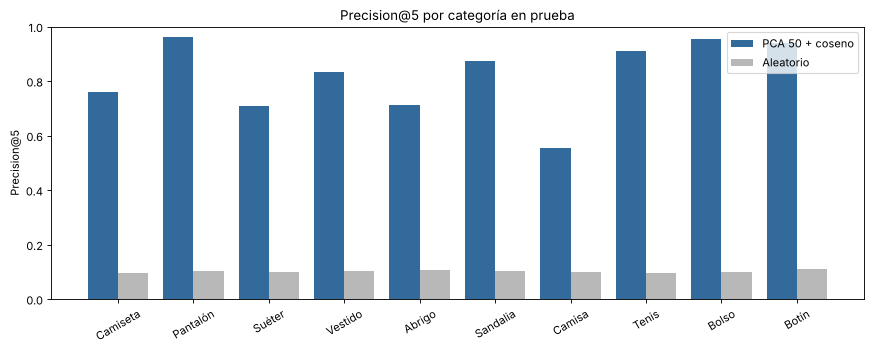

In [11]:
grupos_test = kmeans.predict(Z_test)
posiciones_test = VARIANTES[VARIANTE_ELEGIDA](X_test, Z_test, grupos_test)
aciertos_test = aciertos(y_test, y_train, posiciones_test)
p5_test = float(aciertos_test.mean())
media_azar, desv_azar = precision_aleatoria(y_test)
posiciones_azar = recomendaciones_aleatorias(len(y_test), len(y_train), 5, semilla=SEMILLA)
aciertos_azar = aciertos(y_test, y_train, posiciones_azar)

print(f"Prueba, {VARIANTE_ELEGIDA}: Precision@5 = {p5_test:.4f}")
print(f"Prueba, aleatorio (5 semillas): Precision@5 = {media_azar:.4f} ± {desv_azar:.4f}")
print(f"Mejora sobre el azar: {p5_test / media_azar:.1f} veces")

resultado_final = [
    {"conjunto": "prueba", "variante": VARIANTE_ELEGIDA, "precision_at_5": round(p5_test, 4)},
    {"conjunto": "prueba", "variante": "Aleatorio (media de 5 semillas)", "precision_at_5": round(media_azar, 4)},
]
guardar_tabla_ns("recomendador_resultado_prueba.csv", resultado_final)

por_categoria = []
print("\nCategoría  | Recomendador | Aleatorio")
for c in range(10):
    sel = y_test == c
    fila = {"id": c, "categoria": CATEGORIAS[c],
            "precision_at_5_recomendador": round(float(aciertos_test[sel].mean()), 4),
            "precision_at_5_aleatorio": round(float(aciertos_azar[sel].mean()), 4)}
    por_categoria.append(fila)
    print(f"{CATEGORIAS[c]:10} | {fila['precision_at_5_recomendador']:12.3f} | {fila['precision_at_5_aleatorio']:9.3f}")
guardar_tabla_ns("recomendador_precision_por_categoria_prueba.csv", por_categoria)

fig, ax = plt.subplots(figsize=(11, 4.5))
posiciones_x = np.arange(10)
ax.bar(posiciones_x - 0.2, [f["precision_at_5_recomendador"] for f in por_categoria], 0.4,
       label=VARIANTE_ELEGIDA, color="#326b9b")
ax.bar(posiciones_x + 0.2, [f["precision_at_5_aleatorio"] for f in por_categoria], 0.4,
       label="Aleatorio", color="#b8b8b8")
ax.set_xticks(posiciones_x, CATEGORIAS, rotation=30)
ax.set_ylim(0, 1); ax.set_ylabel("Precision@5")
ax.set_title("Precision@5 por categoría en prueba")
ax.legend()
fig.tight_layout()
guardar_figura_ns(fig, "recomendador_precision_por_categoria.png")
plt.show(); plt.close(fig)

### 6.3 Ejemplos de aciertos y fallos

Arriba, consultas de prueba con las cinco recomendaciones correctas; abajo, consultas con más fallos. La tabla siguiente cuenta con qué categorías se confunden más las recomendaciones.

Consultas con 5 de 5 correctas: 63.9%
Consultas con 0 o 1 correctas: 9.5%

Confusiones más frecuentes (consulta -> recomendada):
  Camisa    -> Camiseta    871 (17.4%)
  Camiseta  -> Camisa      806 (16.1%)
  Abrigo    -> Suéter      694 (13.9%)
  Suéter    -> Abrigo      654 (13.1%)
  Suéter    -> Camisa      594 (11.9%)
  Camisa    -> Suéter      587 (11.7%)
  Abrigo    -> Camisa      540 (10.8%)
  Camisa    -> Abrigo      520 (10.4%)
  Sandalia  -> Tenis       362 (7.2%)
  Tenis     -> Botín       319 (6.4%)


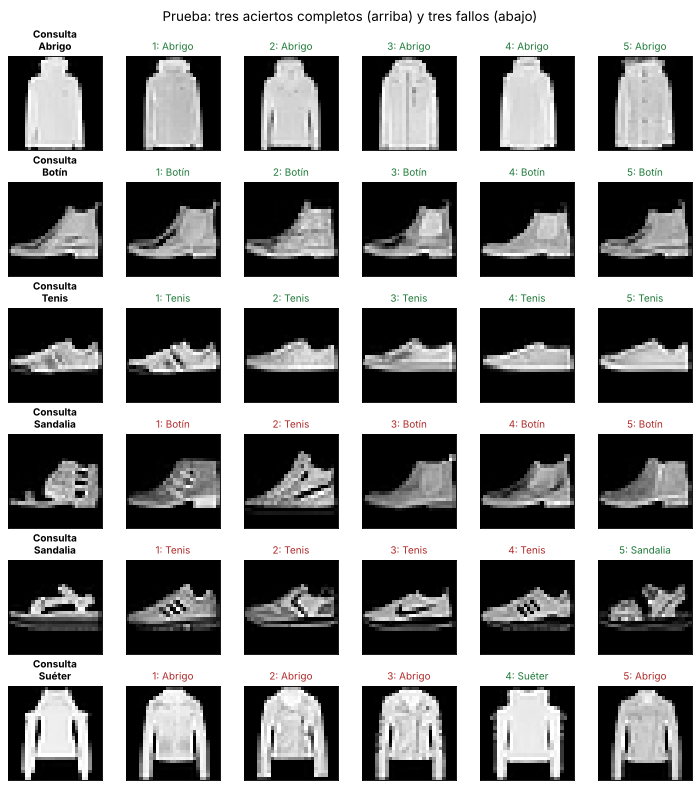

In [12]:
rng = np.random.default_rng(SEMILLA)
n_aciertos = aciertos_test.sum(axis=1)
buenos = rng.choice(np.flatnonzero(n_aciertos == 5), size=3, replace=False)
malos = rng.choice(np.flatnonzero(n_aciertos <= 1), size=3, replace=False)

fig, ejes = plt.subplots(6, 6, figsize=(9, 10))
for fila, consulta in enumerate(np.concatenate([buenos, malos])):
    mostrar_recomendaciones(ejes[fila], X_test[consulta], y_test[consulta], posiciones_test[consulta])
fig.suptitle("Prueba: tres aciertos completos (arriba) y tres fallos (abajo)")
fig.tight_layout()
guardar_figura_ns(fig, "recomendador_aciertos_y_fallos.png")
plt.show(); plt.close(fig)

print(f"Consultas con 5 de 5 correctas: {np.mean(n_aciertos == 5):.1%}")
print(f"Consultas con 0 o 1 correctas: {np.mean(n_aciertos <= 1):.1%}")

confusiones = tabla_contingencia(np.repeat(y_test, 5), y_train[posiciones_test].ravel())
np.fill_diagonal(confusiones, 0)
pares = sorted(((confusiones[a, b], a, b) for a in range(10) for b in range(10) if confusiones[a, b] > 0), reverse=True)[:10]
filas_conf = [{"consulta": CATEGORIAS[a], "recomendada": CATEGORIAS[b], "recomendaciones": int(n),
               "porcentaje_de_la_categoria": round(100 * n / (5 * np.sum(y_test == a)), 1)} for n, a, b in pares]
guardar_tabla_ns("recomendador_confusiones_prueba.csv", filas_conf)
print("\nConfusiones más frecuentes (consulta -> recomendada):")
for f in filas_conf:
    print(f"  {f['consulta']:9} -> {f['recomendada']:9} {f['recomendaciones']:5} ({f['porcentaje_de_la_categoria']}%)")

### 6.4 Descargar los resultados

Crea un ZIP con las tablas y gráficas de este notebook. Descarga también el notebook ejecutado (Archivo > Descargar > `.ipynb`).

In [13]:
import zipfile

ruta_zip = Path("StyleBot_06_recomendacion.zip")
with zipfile.ZipFile(ruta_zip, "w", zipfile.ZIP_DEFLATED) as comprimido:
    for ruta in sorted(CARPETA_NO_SUPERVISADO.rglob("*")):
        if ruta.is_file():
            comprimido.write(ruta, ruta.relative_to(CARPETA_NO_SUPERVISADO))
print("Archivo preparado:", ruta_zip.resolve())

try:
    from google.colab import files
except ImportError:
    print("Fuera de Colab: abre el ZIP en la ruta indicada arriba.")
else:
    files.download(str(ruta_zip))